# Lab 10 – ILLM (AI463)
**Institute:** SVNIT, Surat | **B.Tech 4th Year (7th Sem)**

This notebook covers:
- **Task 1:** Midsem Questions 2, 4, and 5
- **Task 2:** Fine-tuning a multilingual BERT model for Language Identification


---
# Task 1 – Midsem Questions

## Question 2 – Beam Search Decoding

**Vocabulary:** V = {cat, sat, mat, `</s>`}

| Step | Conditional Probabilities |
|------|---------------------------|
| t=1  | P(cat\|`<s>`)=0.5, P(sat\|`<s>`)=0.3, P(mat\|`<s>`)=0.2 |
| t=2  | P(sat\|cat)=0.6, P(mat\|cat)=0.3, P(`</s>`\|cat)=0.1, P(cat\|sat)=0.2, P(mat\|sat)=0.7, P(`</s>`\|sat)=0.1 |
| t=3  | P(mat\|cat,sat)=0.8, P(`</s>`\|cat,sat)=0.2, P(cat\|sat,mat)=0.1, P(`</s>`\|sat,mat)=0.9 |

Trace Beam Search with **k=2**. Identify final sequence. Why are P(cat|mat) and P(sat|mat) ignored?


In [1]:
from collections import defaultdict

p_t1 = {'cat': 0.5, 'sat': 0.3, 'mat': 0.2}
p_t2 = {
    ('cat', 'sat'):   0.6, ('cat', 'mat'):   0.3, ('cat', '</s>'): 0.1,
    ('sat', 'cat'):   0.2, ('sat', 'mat'):   0.7, ('sat', '</s>'): 0.1,
}
p_t3 = {
    (('cat', 'sat'), 'mat'):   0.8,
    (('cat', 'sat'), '</s>'): 0.2,
    (('sat', 'mat'), 'cat'):   0.1,
    (('sat', 'mat'), '</s>'): 0.9,
}

BEAM_WIDTH = 2
print('=' * 65)
print(f'  BEAM SEARCH DECODING  (beam width k = {BEAM_WIDTH})')
print('=' * 65)

# t=1
print('\n-- t=1: Expand from <s> -----------------------------------')
hyps = [([w], p) for w, p in p_t1.items()]
for seq, p in sorted(hyps, key=lambda x: -x[1]):
    print(f'   {seq}  ->  P = {p:.4f}')
hyps.sort(key=lambda x: -x[1])
beam = hyps[:BEAM_WIDTH]
print(f'\n  Top-{BEAM_WIDTH} retained: {[s for s,_ in beam]}')

# t=2
print('\n-- t=2: Expand beam candidates ---------------------------')
hyps2 = []
for seq, cum in beam:
    prev = seq[-1]
    for (ctx, nxt), cp in p_t2.items():
        if ctx == prev:
            new_p = cum * cp
            new_s = seq + [nxt]
            hyps2.append((new_s, new_p))
            print(f'   {str(new_s):<38}  {cum:.4f} x {cp:.2f} = {new_p:.4f}')
hyps2.sort(key=lambda x: -x[1])
beam = hyps2[:BEAM_WIDTH]
print(f'\n  Top-{BEAM_WIDTH} retained: {[s for s,_ in beam]}')

# t=3
print('\n-- t=3: Expand beam candidates ---------------------------')
hyps3 = []
for seq, cum in beam:
    ctx = tuple(seq[-2:])
    for (c, nxt), cp in p_t3.items():
        if c == ctx:
            new_p = cum * cp
            new_s = seq + [nxt]
            hyps3.append((new_s, new_p))
            print(f'   {str(new_s):<42}  {cum:.4f} x {cp:.2f} = {new_p:.4f}')
hyps3.sort(key=lambda x: -x[1])
print(f'\n  Final output: {hyps3[0][0]}  with P = {hyps3[0][1]:.4f}')


  BEAM SEARCH DECODING  (beam width k = 2)

-- t=1: Expand from <s> -----------------------------------
   ['cat']  ->  P = 0.5000
   ['sat']  ->  P = 0.3000
   ['mat']  ->  P = 0.2000

  Top-2 retained: [['cat'], ['sat']]

-- t=2: Expand beam candidates ---------------------------
   ['cat', 'sat']                          0.5000 x 0.60 = 0.3000
   ['cat', 'mat']                          0.5000 x 0.30 = 0.1500
   ['cat', '</s>']                         0.5000 x 0.10 = 0.0500
   ['sat', 'cat']                          0.3000 x 0.20 = 0.0600
   ['sat', 'mat']                          0.3000 x 0.70 = 0.2100
   ['sat', '</s>']                         0.3000 x 0.10 = 0.0300

  Top-2 retained: [['cat', 'sat'], ['sat', 'mat']]

-- t=3: Expand beam candidates ---------------------------
   ['cat', 'sat', 'mat']                       0.3000 x 0.80 = 0.2400
   ['cat', 'sat', '</s>']                      0.3000 x 0.20 = 0.0600
   ['sat', 'mat', 'cat']                       0.2100 x 0.10 = 0.0210

### Beam Search – Explanation

| Step | Expanded | Top-2 Retained |
|------|----------|----------------|
| t=1 | [cat]=0.50, [sat]=0.30, [mat]=0.20 | **[cat], [sat]** |
| t=2 | [cat,sat]=0.30, [cat,mat]=0.15, [cat,`</s>`]=0.05, [sat,cat]=0.06, [sat,mat]=0.21, [sat,`</s>`]=0.03 | **[cat,sat]=0.30, [sat,mat]=0.21** |
| t=3 | [cat,sat,mat]=0.24, [cat,sat,`</s>`]=0.06, [sat,mat,`</s>`]=0.189, [sat,mat,cat]=0.021 | **[cat,sat,mat]=0.24 wins** |

**Final output sequence: `cat sat mat`**

#### Why are P(cat|mat) and P(sat|mat) ignored?
`mat` is pruned at t=1 (ranks 3rd, below beam width=2). No active beam ends with `mat`, so transitions conditioned on `mat` are never required. Beam search only computes transitions for tokens currently in the beam.


---
## Question 4 – Byte-Pair Encoding (BPE)

**Corpus:**
```
low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest
```

Apply BPE for **2 merges**. Show vocabulary and merge rules. How does BPE handle OOV words?


In [2]:
from collections import Counter, defaultdict

def get_vocab(corpus_lines):
    vocab = Counter()
    for line in corpus_lines:
        for word in line.strip().split():
            vocab[tuple(list(word) + ['</w>'])] += 1
    return vocab

def get_pair_stats(vocab):
    pairs = defaultdict(int)
    for word, freq in vocab.items():
        syms = list(word)
        for i in range(len(syms) - 1):
            pairs[(syms[i], syms[i+1])] += freq
    return pairs

def merge_vocab(pair, vocab):
    merged = ''.join(pair)
    new_vocab = {}
    for word_t, freq in vocab.items():
        word = list(word_t); new_word = []; i = 0
        while i < len(word):
            if i < len(word)-1 and word[i] == pair[0] and word[i+1] == pair[1]:
                new_word.append(merged); i += 2
            else:
                new_word.append(word[i]); i += 1
        new_vocab[tuple(new_word)] = freq
    return new_vocab

corpus = [
    'low lower low lower lowest',
    'low lowest low lowest',
    'low new',
    'newest widest widest',
    'new widest',
]

vocab = get_vocab(corpus)
print('=' * 65)
print('  BYTE-PAIR ENCODING  (2 merges)')
print('=' * 65)
print('\n-- Initial Vocabulary ------------------------------------')
for word, freq in sorted(vocab.items(), key=lambda x: -x[1]):
    print(f"  {' '.join(word):<35}  freq={freq}")

merge_rules = []
for merge_num in range(1, 3):
    stats = get_pair_stats(vocab)
    best  = max(stats, key=stats.get)
    merge_rules.append(best)
    print(f"\n-- Merge #{merge_num}: '{best[0]}' + '{best[1]}' -> "
          f"'{''.join(best)}' (freq={stats[best]}) --")
    vocab = merge_vocab(best, vocab)
    for word, freq in sorted(vocab.items(), key=lambda x: -x[1]):
        print(f"  {' '.join(word):<35}  freq={freq}")

final_tokens = sorted({t for word in vocab for t in word})
print('\n-- Merge Rules -------------------------------------------')
for i, r in enumerate(merge_rules, 1):
    print(f"  Rule {i}: {r[0]} + {r[1]} -> {''.join(r)}")
print('\n-- Final Vocabulary (unique tokens) ----------------------')
print(' ', final_tokens)


  BYTE-PAIR ENCODING  (2 merges)

-- Initial Vocabulary ------------------------------------
  l o w </w>                           freq=5
  l o w e s t </w>                     freq=3
  w i d e s t </w>                     freq=3
  l o w e r </w>                       freq=2
  n e w </w>                           freq=2
  n e w e s t </w>                     freq=1

-- Merge #1: 'l' + 'o' -> 'lo' (freq=10) --
  lo w </w>                            freq=5
  lo w e s t </w>                      freq=3
  w i d e s t </w>                     freq=3
  lo w e r </w>                        freq=2
  n e w </w>                           freq=2
  n e w e s t </w>                     freq=1

-- Merge #2: 'lo' + 'w' -> 'low' (freq=10) --
  low </w>                             freq=5
  low e s t </w>                       freq=3
  w i d e s t </w>                     freq=3
  low e r </w>                         freq=2
  n e w </w>                           freq=2
  n e w e s t </w>               

### BPE – Explanation

**Initial word representations** (characters + `</w>` end-of-word marker):

| Word | Representation | Freq |
|------|---------------|------|
| low | `l o w </w>` | 5 |
| lower | `l o w e r </w>` | 2 |
| lowest | `l o w e s t </w>` | 3 |
| new | `n e w </w>` | 2 |
| newest | `n e w e s t </w>` | 1 |
| widest | `w i d e s t </w>` | 3 |

**Merge 1:** `l + o → lo` (freq = 10)  
**Merge 2:** `lo + w → low` (freq = 10)

#### How BPE Handles OOV Words
1. Any unseen word is split into **individual characters** (always in the base vocab).
2. The learned **merge rules** are applied in the same order as training.
3. Sub-word tokens are produced — no unknown-word symbol is ever emitted.

**Example:** OOV `'lowing'` → `l o w i n g </w>` → Merge 1: `lo w i n g </w>` → Merge 2: `low i n g </w>`.


---
## Question 5 – TF-IDF & Doc2Vec

| Doc | Text | Class |
|-----|------|-------|
| D1 | machine learning is useful | Technology |
| D2 | machine learning is powerful | Technology |
| D3 | learning language is useful | Language |
| D4 | language processing is useful | Language |

1. Vocabulary & TF-IDF of each word
2. Class representation via TF-IDF
3. Doc2Vec architecture (PV-DM)


In [3]:
import math
from collections import Counter

docs = {
    'D1': 'machine learning is useful',
    'D2': 'machine learning is powerful',
    'D3': 'learning language is useful',
    'D4': 'language processing is useful',
}
labels = {'D1':'Technology','D2':'Technology','D3':'Language','D4':'Language'}
tokenised = {d: t.split() for d, t in docs.items()}
vocab = sorted({w for t in tokenised.values() for w in t})
N = len(docs)

def tf(tokens):
    c = Counter(tokens)
    return {w: c[w]/len(tokens) for w in c}

def idf(word):
    df = sum(1 for t in tokenised.values() if word in t)
    return math.log10(N / df)

TF    = {d: tf(tokenised[d]) for d in docs}
IDF   = {w: idf(w) for w in vocab}
TFIDF = {d: {w: round(TF[d].get(w,0)*IDF[w],4) for w in vocab} for d in docs}

print('=' * 70)
print('  VOCABULARY:', vocab)
print('=' * 70)

hdr = f"  {'Word':<14}" + ''.join(f'{d:>9}' for d in docs)
print('\n-- TF (term_count / doc_length) ---')
print(hdr); print('-' * 50)
for w in vocab:
    print(f'  {w:<14}' + ''.join(f'{TF[d].get(w,0):>9.4f}' for d in docs))

print(f'\n-- IDF = log10({N}/df) ------------')
print(f"  {'Word':<14} {'DF':>4} {'IDF':>9}"); print('-' * 32)
for w in vocab:
    df = sum(1 for t in tokenised.values() if w in t)
    print(f'  {w:<14} {df:>4} {IDF[w]:>9.4f}')

print('\n-- TF-IDF Matrix ------------------')
print(hdr); print('-' * 50)
for w in vocab:
    print(f'  {w:<14}' + ''.join(f'{TFIDF[d][w]:>9.4f}' for d in docs))


  VOCABULARY: ['is', 'language', 'learning', 'machine', 'powerful', 'processing', 'useful']

-- TF (term_count / doc_length) ---
  Word                 D1       D2       D3       D4
--------------------------------------------------
  is               0.2500   0.2500   0.2500   0.2500
  language         0.0000   0.0000   0.2500   0.2500
  learning         0.2500   0.2500   0.2500   0.0000
  machine          0.2500   0.2500   0.0000   0.0000
  powerful         0.0000   0.2500   0.0000   0.0000
  processing       0.0000   0.0000   0.0000   0.2500
  useful           0.2500   0.0000   0.2500   0.2500

-- IDF = log10(4/df) ------------
  Word             DF       IDF
--------------------------------
  is                4    0.0000
  language          2    0.3010
  learning          3    0.1249
  machine           2    0.3010
  powerful          1    0.6021
  processing        1    0.6021
  useful            3    0.1249

-- TF-IDF Matrix ------------------
  Word                 D1       D2 

In [4]:
from collections import defaultdict

class_docs = defaultdict(list)
for d, lbl in labels.items():
    class_docs[lbl].append(d)

class_vec = {}
for cls, ds in class_docs.items():
    class_vec[cls] = {w: round(sum(TFIDF[d][w] for d in ds)/len(ds),4) for w in vocab}

print('=' * 65)
print('  CLASS REPRESENTATION (average TF-IDF across class documents)')
print('=' * 65)
hdr2 = f"  {'Word':<14}" + ''.join(f'{c:>14}' for c in class_vec)
print(hdr2); print('-' * 44)
for w in vocab:
    print(f'  {w:<14}' + ''.join(f'{class_vec[c][w]:>14.4f}' for c in class_vec))
print('\nStrategy: average TF-IDF per class. '
      'Classify new doc by max cosine similarity to class vector.')


  CLASS REPRESENTATION (average TF-IDF across class documents)
  Word              Technology      Language
--------------------------------------------
  is                    0.0000        0.0000
  language              0.0000        0.0753
  learning              0.0312        0.0156
  machine               0.0753        0.0000
  powerful              0.0752        0.0000
  processing            0.0000        0.0752
  useful                0.0156        0.0312

Strategy: average TF-IDF per class. Classify new doc by max cosine similarity to class vector.


In [5]:
arch = """
DOC2VEC - PV-DM (Paragraph Vector, Distributed Memory)
Le & Mikolov, 2014

  Document ID (unique per doc)       Context words [w_{t-k},...,w_{t-1}]
         |                                          |
  [Paragraph Matrix D x d]          [Word Embedding Matrix W (V x d)]
         |                                          |
         +------------- Concatenate / Average ------+
                                     |
                              [Hidden Layer (dim=d)]
                                     |
                         [Softmax] -> predict next word w_t

Training Objective:
  maximize  SUM log P(w_t | D_i, w_{t-k}, ..., w_{t-1})

Key points:
  - Each document has a UNIQUE trainable paragraph vector.
  - Word vectors are SHARED across all documents.
  - At inference: freeze word vectors; optimize new doc vector via SGD.
  - Alternative: PV-DBOW -- predict words from doc vector alone (no word order).
"""
print(arch)



DOC2VEC - PV-DM (Paragraph Vector, Distributed Memory)
Le & Mikolov, 2014

  Document ID (unique per doc)       Context words [w_{t-k},...,w_{t-1}]
         |                                          |
  [Paragraph Matrix D x d]          [Word Embedding Matrix W (V x d)]
         |                                          |
         +------------- Concatenate / Average ------+
                                     |
                              [Hidden Layer (dim=d)]
                                     |
                         [Softmax] -> predict next word w_t

Training Objective:
  maximize  SUM log P(w_t | D_i, w_{t-k}, ..., w_{t-1})

Key points:
  - Each document has a UNIQUE trainable paragraph vector.
  - Word vectors are SHARED across all documents.
  - At inference: freeze word vectors; optimize new doc vector via SGD.
  - Alternative: PV-DBOW -- predict words from doc vector alone (no word order).



### TF-IDF & Doc2Vec – Summary

**TF-IDF key observations:**
- `is` appears in all 4 docs → IDF = log₁₀(4/4) = **0** → TF-IDF = 0
- `machine`, `powerful` → Technology only → high TF-IDF
- `language`, `processing` → Language only → high TF-IDF

**Class Representation:**
$$C_{\text{Tech}} = \frac{D_1+D_2}{2}, \quad C_{\text{Lang}} = \frac{D_3+D_4}{2}$$

**Doc2Vec (PV-DM):** Paragraph vectors encode document semantics. Trained jointly with word embeddings to predict the next word given the paragraph vector + context words.


---
# Task 2 – Fine-tuning BERT for Language Identification

Fine-tune a multilingual BERT model (e.g., MuRIL, mBERT) on the language identification dataset from Lab Assignment 1, and compare its performance with Logistic Regression, MLP, LSTM, GRU, and FastText.

> **Note:** Run on Google Colab or Kaggle Notebook for GPU support.  
> A **base** model variant is used to keep compute tractable.


In [6]:
# Install dependencies (uncomment when running for the first time)
# !pip install transformers datasets scikit-learn torch -q


In [7]:
import os
# Prevent OpenMP library conflict/crashes on Windows
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

# Import PyTorch and Transformers first before scikit-learn/pandas
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup,
)

import random
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)


Device: cuda


In [8]:
# ── Load dataset from dataset_sentences.pkl (Lab Assignment 1) ────────────
# Structure: dict { lang_code: [sentence1, sentence2, ...] }
# 23 Indian languages, ~981 sentences each

import pickle

PKL_PATH = 'dataset_sentences.pkl'

with open(PKL_PATH, 'rb') as f:
    dataset_sentences = pickle.load(f)

# Flatten into (text, language) pairs
rows = []
for lang, sents in dataset_sentences.items():
    for s in sents:
        rows.append({'text': s, 'language': lang})

df = pd.DataFrame(rows)
print('Languages loaded:', sorted(df['language'].unique()))
print(df['language'].value_counts())
print('Total samples:', len(df))


Languages loaded: ['asm_Beng', 'ben_Beng', 'brx_Deva', 'doi_Deva', 'gom_Deva', 'guj_Gujr', 'hin_Deva', 'kan_Knda', 'kas_Arab', 'khasi', 'mai_Deva', 'mal_Mlym', 'mar_Deva', 'mni_Mtei', 'npi_Deva', 'ory_Orya', 'pan_Guru', 'san_Deva', 'santhali', 'snd_Deva', 'tam_Taml', 'tel_Telu', 'urd_Arab']
language
asm_Beng    981
mni_Mtei    981
khasi       981
urd_Arab    981
tel_Telu    981
tam_Taml    981
snd_Deva    981
san_Deva    981
pan_Guru    981
ory_Orya    981
npi_Deva    981
mar_Deva    981
ben_Beng    981
mal_Mlym    981
mai_Deva    981
kas_Arab    981
kan_Knda    981
hin_Deva    981
guj_Gujr    981
gom_Deva    981
doi_Deva    981
brx_Deva    981
santhali    981
Name: count, dtype: int64
Total samples: 22563


In [9]:
le = LabelEncoder()
df['label'] = le.fit_transform(df['language'])
NUM_LABELS = len(le.classes_)
print('Classes:', list(le.classes_))

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df['label'])
train_df, val_df = train_test_split(
    train_df, test_size=0.1, random_state=SEED, stratify=train_df['label'])
print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')


Classes: ['asm_Beng', 'ben_Beng', 'brx_Deva', 'doi_Deva', 'gom_Deva', 'guj_Gujr', 'hin_Deva', 'kan_Knda', 'kas_Arab', 'khasi', 'mai_Deva', 'mal_Mlym', 'mar_Deva', 'mni_Mtei', 'npi_Deva', 'ory_Orya', 'pan_Guru', 'san_Deva', 'santhali', 'snd_Deva', 'tam_Taml', 'tel_Telu', 'urd_Arab']
Train: 16245 | Val: 1805 | Test: 4513


In [10]:
# Supported multilingual base models for Indian languages:
#   'google/muril-base-cased'                    <- MuRIL (recommended)
#   'google-bert/bert-base-multilingual-cased'   <- mBERT
#   'ai4bharat/indic-bert'                       <- IndicBERT
#   'FacebookAI/xlm-roberta-base'                <- XLM-RoBERTa

MODEL_NAME = 'google/muril-base-cased'
MAX_LEN    = 128
BATCH_SIZE = 16
EPOCHS     = 3
LR         = 2e-5

print(f'Model: {MODEL_NAME}')
print(f'Max sequence length: {MAX_LEN}')


Model: google/muril-base-cased
Max sequence length: 128


In [11]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class LangIDDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_len):
        self.texts   = dataframe['text'].tolist()
        self.labels  = dataframe['label'].tolist()
        self.tok     = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tok(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
        )
        return {
            'input_ids':      enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'labels':         torch.tensor(self.labels[idx], dtype=torch.long),
        }

train_ds = LangIDDataset(train_df, tokenizer, MAX_LEN)
val_ds   = LangIDDataset(val_df,   tokenizer, MAX_LEN)
test_ds  = LangIDDataset(test_df,  tokenizer, MAX_LEN)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE)
print('Dataloaders ready.')


tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

c:\Users\dhruv\Downloads\ILLM_SVNIT\venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dhruv\.cache\huggingface\hub\models--google--muril-base-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

Dataloaders ready.


In [12]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=NUM_LABELS
).to(DEVICE)

optimizer   = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler   = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps,
)
print('Model loaded.')
print('Trainable parameters:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))


pytorch_model.bin:   0%|          | 0.00/953M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/muril-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded.
Trainable parameters: 237573911


In [13]:
def evaluate(loader):
    model.eval()
    all_preds, all_labels, total_loss = [], [], 0
    with torch.no_grad():
        for batch in loader:
            ids  = batch['input_ids'].to(DEVICE)
            mask = batch['attention_mask'].to(DEVICE)
            lbls = batch['labels'].to(DEVICE)
            out  = model(input_ids=ids, attention_mask=mask, labels=lbls)
            total_loss += out.loss.item()
            preds = torch.argmax(out.logits, dim=-1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(lbls.cpu().numpy())
    return total_loss / len(loader), accuracy_score(all_labels, all_preds)

history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_acc': []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0
    for batch in train_loader:
        optimizer.zero_grad()
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attention_mask'].to(DEVICE)
        lbls = batch['labels'].to(DEVICE)
        out  = model(input_ids=ids, attention_mask=mask, labels=lbls)
        out.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); scheduler.step()
        train_loss += out.loss.item()
    train_loss /= len(train_loader)
    val_loss, val_acc = evaluate(val_loader)
    history['epoch'].append(epoch)
    history['train_loss'].append(round(train_loss, 4))
    history['val_loss'].append(round(val_loss, 4))
    history['val_acc'].append(round(val_acc, 4))
    print(f'Epoch {epoch}/{EPOCHS}  '
          f'Train Loss: {train_loss:.4f}  '
          f'Val Loss: {val_loss:.4f}  '
          f'Val Acc: {val_acc:.4f}')

print('\nTraining History:')
print(pd.DataFrame(history).to_string(index=False))


c:\Users\dhruv\Downloads\ILLM_SVNIT\venv\Lib\site-packages\transformers\models\bert\modeling_bert.py:440: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  attn_output = torch.nn.functional.scaled_dot_product_attention(


Epoch 1/3  Train Loss: 2.5234  Val Loss: 1.5531  Val Acc: 0.8864
Epoch 2/3  Train Loss: 0.9538  Val Loss: 0.5382  Val Acc: 0.9053
Epoch 3/3  Train Loss: 0.4251  Val Loss: 0.3804  Val Acc: 0.9175

Training History:
 epoch  train_loss  val_loss  val_acc
     1      2.5234    1.5531   0.8864
     2      0.9538    0.5382   0.9053
     3      0.4251    0.3804   0.9175


In [14]:
# ── Test evaluation ────────────────────────────────────────────────────────
model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for batch in test_loader:
        ids  = batch['input_ids'].to(DEVICE)
        mask = batch['attention_mask'].to(DEVICE)
        lbls = batch['labels'].to(DEVICE)
        out  = model(input_ids=ids, attention_mask=mask)
        preds = torch.argmax(out.logits, dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(lbls.cpu().numpy())

bert_acc = accuracy_score(all_true, all_preds)
short_name = MODEL_NAME.split('/')[-1]
print(f'\n{short_name} Test Accuracy: {bert_acc:.4f}')
print('\nClassification Report:')
print(classification_report(all_true, all_preds, target_names=le.classes_))



muril-base-cased Test Accuracy: 0.9187

Classification Report:
              precision    recall  f1-score   support

    asm_Beng       1.00      0.99      0.99       196
    ben_Beng       0.98      1.00      0.99       196
    brx_Deva       0.93      0.87      0.90       196
    doi_Deva       0.94      0.91      0.93       196
    gom_Deva       0.87      0.63      0.73       196
    guj_Gujr       1.00      1.00      1.00       196
    hin_Deva       0.87      0.96      0.91       197
    kan_Knda       0.99      1.00      0.99       197
    kas_Arab       0.99      0.99      0.99       196
       khasi       0.98      0.99      0.99       196
    mai_Deva       0.92      0.94      0.93       197
    mal_Mlym       1.00      1.00      1.00       196
    mar_Deva       0.73      0.90      0.80       196
    mni_Mtei       0.78      0.04      0.07       196
    npi_Deva       0.99      0.98      0.99       197
    ory_Orya       0.99      1.00      1.00       196
    pan_Guru     

In [17]:
# ── Model comparison table ─────────────────────────────────────────────────
# Fill in the accuracies from your Lab 1 models below.
comparison = pd.DataFrame({
    'Model':    ['Logistic Regression', 'MLP', 'LSTM', 'GRU',
                 'FastText', f'BERT ({MODEL_NAME.split("/")[-1]})'],
    'Accuracy': [0.7770, 0.7770, 0.5169, 0.7754, 0.8584, bert_acc],
    # Replace None values with actual accuracies from Lab 1
})
print('\n-- Model Comparison ------------------------------------------')
print(comparison.to_string(index=False))



-- Model Comparison ------------------------------------------
                  Model  Accuracy
    Logistic Regression  0.777000
                    MLP  0.777000
                   LSTM  0.516900
                    GRU  0.775400
               FastText  0.858400
BERT (muril-base-cased)  0.918679


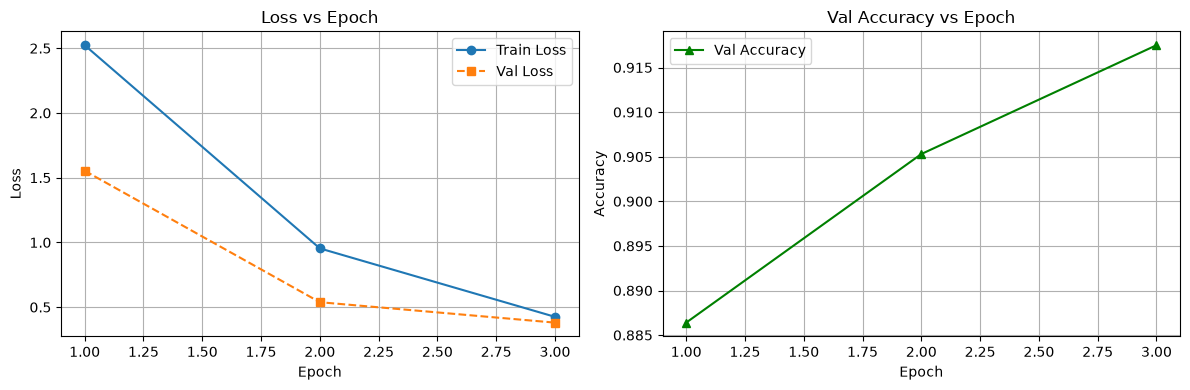

Saved: bert_training_curves.png


In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ep = history['epoch']

axes[0].plot(ep, history['train_loss'], 'o-',  label='Train Loss')
axes[0].plot(ep, history['val_loss'],   's--', label='Val Loss')
axes[0].set_title('Loss vs Epoch'); axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(True)

axes[1].plot(ep, history['val_acc'], '^-g', label='Val Accuracy')
axes[1].set_title('Val Accuracy vs Epoch'); axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy'); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.savefig('bert_training_curves.png', dpi=150)
plt.show()
print('Saved: bert_training_curves.png')


### Task 2 – Notes

| Model | Strength |
|-------|----------|
| Logistic Regression | Strong TF-IDF baseline |
| MLP | Non-linear bag-of-words |
| LSTM / GRU | Sequential character/word context |
| FastText | Sub-word n-gram + fast inference |
| **MuRIL (BERT)** | Pre-trained transformer; understands script & morphology |

**Expected:** BERT/MuRIL outperforms all other models due to pre-training on large multilingual corpora covering Indian scripts.

**Supported base models:**
- `google/muril-base-cased` — MuRIL, purpose-built for 17 Indian languages ✓ recommended
- `google-bert/bert-base-multilingual-cased` — mBERT, covers 104 languages
- `ai4bharat/indic-bert` — IndicBERT trained on AI4Bharat corpus
- `FacebookAI/xlm-roberta-base` — XLM-RoBERTa, strong multilingual performance
- `google/mt5-small` — mT5, encoder-decoder, use encoder output for classification
